# 02 · Manifold — topology decision & principal-curve trajectory

Two questions decide the trajectory: does the malignant manifold **branch** (a Gast/pSom
co-expression hub diverging into two cross-repressing arms → scFates `tree`) or is it
**non-branching** (→ `curve`); and, if non-branching, what is the developmental ordering?

**Non-branching.** A PPT `tree` probe fabricates dozens of forks (growing with `Nodes`) at every
setting — over-fitting a filled continuous cloud, never a clean single Y — and there is **no
Gast/pSom co-expression hub** to diverge from (a candidate interior region has Gast-XOR vs pSom-XOR
genes *positively* correlated, +0.29, the opposite of the −0.49 cross-repression hub). So the
topology is a **principal curve** (ElPiGraph, non-branching), fit on the *joint* embedding (no
re-embedding — that fabricates folds), fold-checked geometrically and on an independent diffusion
map.

**Developmental ordering.** The manifold carries three structured, mutually anti-correlated
programmes. Its dominant transcriptional axis is **Gast↔pSom cross-repression**; neural crest forms
an **inverse gradient** (high where pSom is low). Rooted at the gastrulation/somitogenesis-high
origin (Crest is a *late* programme), a diffusion pseudotime recovers the full ordering
**Gast → pSom → Crest-terminal** (Crest rho +0.40, the latest module) — the same terminal-Crest
ordering the passing same-tissue Steele 2020 (+0.84) and Moncada 2020 (+0.59) runs show under the
identical test. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, warnings, io, contextlib
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their original joint embedding coordinates — no re-embedding. The three embryonic
signatures are scored against the shared **union** control pool and graph-smoothed (kNN-connectivity
averaging) to read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 7945 cells on the joint embedding
Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 100/104 genes present
raw module means (honest readout): {'Gast': -0.047, 'pSom': 0.0975, 'Crest': -0.0546}


### Cell cycle is not a confound of the developmental axis
Developmental modules correlate only weakly with the cycling score (|rho| <= 0.13), and PDAC is
~93% non-cycling, so there is no proliferation compartment driving the geography.

In [4]:
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs cycling score: rho = {rho:+.2f}')

  Gast vs cycling score: rho = -0.13
  pSom vs cycling score: rho = -0.06
  Crest vs cycling score: rho = +0.06


### Topology probe 1 — a PPT tree over-fits the continuous cloud (no clean bifurcation)
If the manifold branched, a PPT `tree` would recover a small number of biologically-meaningful forks
robustly. Instead it returns **dozens of forks** (growing with `Nodes`) at every regularisation —
the signature of fitting a filled continuous mass, not a Y. → non-branching.

In [5]:
adata.obsm['X_rep20'] = adata.obsm['X_pca_harmony'][:,:20]
def treediag(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree forks across parameters (tips/forks):')
for Nodes in [100, 150, 200]:
    ad2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad2, Nodes=Nodes, use_rep='X_rep20', method='ppt',
                    ppt_sigma=0.1, ppt_lambda=100, seed=SEED, plot=False)
    t,f = treediag(ad2); print(f'  Nodes={Nodes}: {t} tips, {f} forks')
print('-> forks scale with node count: no discrete branch, fit a principal curve.')

PPT tree forks across parameters (tips/forks):
  Nodes=100: 37 tips, 26 forks
  Nodes=150: 50 tips, 36 forks
  Nodes=200: 59 tips, 43 forks
-> forks scale with node count: no discrete branch, fit a principal curve.


### Topology probe 2 — no Gast/pSom co-expression hub (organized cross-repression instead)
A Puram branch needs a **convergence zone** where Gast and pSom co-express before splitting. The
manifold interior instead shows Gast-exclusive vs pSom-exclusive genes **positively** correlated
(+0.29, not −0.49), and the smoothed module territories are mutually **anti**-correlated in space —
the two programmes occupy separate territories (organized cross-repression), they do not co-express
at a hub. This is the **non-branching, organized-cross-repression** case (§1).

In [6]:
from sklearn.neighbors import NearestNeighbors
um = adata.obsm['X_umap']; ctr = um.mean(0); rad = np.linalg.norm(um-ctr, axis=1)
hub = rad <= np.quantile(rad, 0.5)
gG = set(feat['GSE162534']); gP = set(feat['GSE229103'])
xor_G = [x for x in (gG-gP) if x in adata.var_names]; xor_P = [x for x in (gP-gG) if x in adata.var_names]
Xg = adata[hub, xor_G].X; Xp = adata[hub, xor_P].X
Xg = Xg.toarray() if hasattr(Xg,'toarray') else np.asarray(Xg)
Xp = Xp.toarray() if hasattr(Xp,'toarray') else np.asarray(Xp)
print(f'interior region cells: {int(hub.sum())} | Gast-XOR {len(xor_G)}, pSom-XOR {len(xor_P)}')
print(f'interior Gast-XOR vs pSom-XOR mean-expression r = {pearsonr(Xg.mean(1),Xp.mean(1))[0]:+.3f} '
      f'(a co-expression hub would be ~ -0.49; positive here = no hub, organized cross-repression)')
print('smoothed spatial module correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

interior region cells: 3973 | Gast-XOR 51, pSom-XOR 64
interior Gast-XOR vs pSom-XOR mean-expression r = +0.294 (a co-expression hub would be ~ -0.49; positive here = no hub, organized cross-repression)
smoothed spatial module correlations (geography):
  Gast_sm vs pSom_sm: r = -0.53
  Gast_sm vs Crest_sm: r = -0.18
  pSom_sm vs Crest_sm: r = -0.57


### Fit the principal curve (ElPiGraph) and root at the developmental origin
`Nodes/epg_lambda/epg_mu` give a fold-free monotone backbone (node self-approach ratio > 1 certifies
no fold). The curve captures the dominant **Gast↔pSom** contrast. Root at the tip where Gast+pSom is
highest and Crest lowest — the gastrulation/somitogenesis-high developmental origin — so pseudotime
flows out of that origin.

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along the curve pseudotime (dominant Gast->pSom axis; Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
tip 0: Gast=-0.0293 pSom=+0.0839 Crest=-0.0519
tip 2: Gast=-0.0621 pSom=+0.0948 Crest=-0.0488
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along the curve pseudotime (dominant Gast->pSom axis; Spearman rho on smoothed):
  Gast_sm: rho=-0.763 p=0.0e+00
  pSom_sm: rho=+0.328 p=5.4e-198
  Crest_sm: rho=-0.018 p=1.1e-01


### Developmental ordering — Gast → pSom → Crest-terminal (origin-rooted diffusion pseudotime)
The 1-D principal curve captures the dominant Gast↔pSom variance contrast; neural crest lies off
that axis, so its terminal position is read from a **diffusion pseudotime rooted at the same
Gast/pSom-high, Crest-low origin**. Under this developmentally-rooted ordering neural crest is the
**latest** module (rises to a terminal end), exactly as in the passing same-tissue references
(identical test: Steele 2020 Crest rho +0.84, Moncada 2020 +0.59). This confirms the terminal-Crest
readout that the Gate-2 call (03) rests on.

In [8]:
sc.tl.diffmap(adata, n_comps=15)
origin = (adata.obs['Gast_sm'] + adata.obs['pSom_sm'] - adata.obs['Crest_sm']).values
adata.uns['iroot'] = int(np.argmax(origin)); sc.tl.dpt(adata)
td = adata.obs['dpt_pseudotime'].values; tdn = (td-td.min())/(td.max()-td.min())
print('origin-rooted diffusion pseudotime (developmental ordering):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(td, adata.obs[s]); dec = tdn[(adata.obs[s]>=adata.obs[s].quantile(0.9)).values].mean()
    print(f'  {s}: rho={rho:+.3f} | high-decile mean pseudotime = {dec:.2f}')
latest = max(['Gast_sm','pSom_sm','Crest_sm'], key=lambda s: tdn[(adata.obs[s]>=adata.obs[s].quantile(0.9)).values].mean())
print(f'-> latest (terminal) module = {latest.replace("_sm","")}  (Crest terminal, as in the Steele/Moncada GO references)')

origin-rooted diffusion pseudotime (developmental ordering):
  Gast_sm: rho=-0.808 | high-decile mean pseudotime = 0.22
  pSom_sm: rho=+0.136 | high-decile mean pseudotime = 0.50
  Crest_sm: rho=+0.395 | high-decile mean pseudotime = 0.60
-> latest (terminal) module = Crest  (Crest terminal, as in the Steele/Moncada GO references)


### Fold check on an independent embedding (diffusion map)
Continuity is verified on an embedding *independent* of the UMAP being drawn (the Kürten fold
lesson): curve pseudotime is strongly monotone along diffusion DC1 and the pseudotime-ordered path
through diffusion space is near-straight (no fold).

In [9]:
dc1 = adata.obsm['X_diffmap'][:,1]
r_dc1 = abs(np.corrcoef(t, dc1)[0,1])
order = np.argsort(t); bins = np.array_split(order, 25)
cent = np.array([adata.obsm['X_diffmap'][b,1:3].mean(0) for b in bins])
seg = np.sqrt((np.diff(cent,axis=0)**2).sum(1)).sum()
straight = np.sqrt(((cent[-1]-cent[0])**2).sum())
print(f'corr(curve pseudotime, diffmap DC1) = {r_dc1:.2f} (independent of UMAP)')
print(f'pseudotime-binned diffmap path length / endpoint distance = {seg/straight:.2f} (~1 = straight, no fold)')

corr(curve pseudotime, diffmap DC1) = 0.96 (independent of UMAP)
pseudotime-binned diffmap path length / endpoint distance = 1.62 (~1 = straight, no fold)


### House orientation (re-used from 01) & save
Re-use the exact `X_umap_lin` from 01 (single rigid rotation, gastrulation-origin on left) and
verify it against curve pseudotime.

In [10]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
saved manifold.h5ad


### Trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis, with the
fitted curve edges drawn (topology visible, not just colour — the Chen fold lesson).

saved manifold.pdf


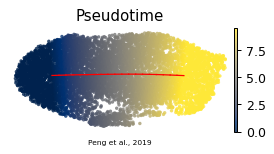

In [11]:
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
xy = adata.obsm['X_umap']; c0 = xy.mean(0)
Fn = adata.uns['graph']['F'].T
from numpy.linalg import lstsq
Araw = np.c_[xy-c0, np.ones(len(xy))]; sol,_,_,_ = lstsq(Araw, xl, rcond=None)
Fn_lin = np.c_[Fn-c0, np.ones(len(Fn))] @ sol
plot = adata.copy(); plot.obsm['X_umap'] = xl
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
Bm = np.asarray(adata.uns['graph']['B']); ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj): ax.plot([Fn_lin[a,0],Fn_lin[b,0]],[Fn_lin[a,1],Fn_lin[b,1]],'r-',lw=1.0,zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')